# First Practical Assignment

## Data Science and Engineering

### DESIGN OF A PARALLELISABLE AND SCALABLE IMAGE FILTERING FUNCTION

**Full name:** ANTONIA ESPERANZA LUENGO SILVA
    
**NIA:** 100613380

In [52]:
import numpy as np
import multiprocess as mp
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cProfile

In [53]:
# Librerias extra
import ctypes
from multiprocess.pool import ThreadPool

In [54]:
F_IMAGE1="Test Images/fence.jpg"
F_IMAGE2="Test Images/chess.jpg"

In [55]:
image1= np.array(Image.open(F_IMAGE1))
image2= np.array(Image.open(F_IMAGE2))

In [56]:
NUMPROCESS=4

# WRITE YOUR CODE AFTER THIS CELL

After this cell, use the preloaded image defined in the F_IMAGE variable, select two predefined filters, and apply them to the image using NUMPROCESS processors. Check the results.


In [57]:
# YOUR CODE STARTS HERE

In [58]:
# Function to limit a value between a lower and upper bound.Boundary replication.
def clamp(value, lower, upper):
    return max(lower, min(value, upper))

# Global variables. Each pararel worker will have acces o these shared memory buffers.
shared_input_img = None
shared_output_img = None
shared_img_shape = None

# Executes when a new worker process is created. It initializes the global variables
def init_worker(input_buffer, output_buffer, shape):
    global shared_input_img, shared_output_img, shared_img_shape
    shared_input_img = input_buffer # asign memory block to the global variable
    shared_output_img = output_buffer
    shared_img_shape = shape

# Filter a range of rows using boundary replication. Each worker process will execute this function.
def worker_filter(start_row, end_row, kernel):
    height, width, channels = shared_img_shape # Get the shape of the image from the global variable
    input_np = np.frombuffer(shared_input_img, dtype=np.uint8).reshape(shared_img_shape) # Create a numpy array view of the shared memory buffer
    output_np = np.frombuffer(shared_output_img, dtype=np.float64).reshape(shared_img_shape)
    pad_h, pad_w = kernel.shape[0] // 2, kernel.shape[1] // 2 # Calculates the radius of the mask
    
    for row in range(start_row, end_row): # Iterate over the assigned rows for this worker, all channels and columns.
        for column in range(width):
            for channel in range(channels):
                accumulator = 0.0 # muliply the neighbor pixel by the corresponding mask coefficient and accumulate the result. In float to avoid overflow.
                for i in range(-pad_h, pad_h + 1):
                    source_row = clamp(row + i, 0, height - 1) # On the fly boundary replication. Prevents black borders.
                    for j in range(-pad_w, pad_w + 1):
                        source_column = clamp(column + j, 0, width - 1)
                        accumulator += (float(input_np[source_row, source_column, channel]) * kernel[i + pad_h, j + pad_w])
                output_np[row, column, channel] = accumulator

# verify that the mask is a 2D matrix with odd dimensions between 1x1 and 5x5, and that all coefficients are finite numbers.
def _validate_mask(filter_mask): 
    mask = np.asarray(filter_mask, dtype=np.float64)
    if mask.ndim != 2:
        raise ValueError("The mask must be a two-dimensional matrix.")
    rows, columns = mask.shape
    if not (1 <= rows <= 5 and 1 <= columns <= 5) or rows % 2 == 0 or columns % 2 == 0:
        raise ValueError("The mask must have odd dimensions between 1x1 and 5x5.")
    if not np.all(np.isfinite(mask)):
        raise ValueError("The mask coefficients must be finite numbers.")
    return mask

# Orquestador
def image_filter(
    image: np.ndarray,
    filter: np.ndarray,
    numprocs: int,
    is_conv: int,
    norm: int,
) -> np.ndarray:
  if isinstance(image, str):
    image = np.array(Image.open(image))
  image_array = np.asarray(image)

# Validate input parameters
  if image_array.ndim not in (2, 3) or image_array.size == 0:
    raise ValueError("The image must be a non-empty 2D or 3D array.")
  if image_array.ndim == 3 and image_array.shape[2] not in (1, 3, 4):
    raise ValueError("The image must have one, three, or four channels.")
  if not isinstance(numprocs, (int, np.integer)) or numprocs < 1:
    raise ValueError("numprocs must be a positive integer.")
  if is_conv not in (0, 1) or norm not in (0, 1):
    raise ValueError("is_conv and norm must be either 0 or 1.")

# Validate the filter mask
  mask = _validate_mask(filter)
  original_was_grayscale = image_array.ndim == 2 # If the image is grayscale, add a new axis to make it 3D for consistent processing.
  if original_was_grayscale: 
    image_array = image_array[:, :, np.newaxis]

  image_uint8 = np.clip(image_array, 0, 255).astype(np.uint8, copy=False) # Clip the image to the range [0, 255] and convert it to uint8.
  height, width, channels = image_uint8.shape

  if is_conv == 1: # Flip the mask for convolution. In convolution, the kernel is flipped both horizontally and vertically before applying it to the image.
    mask = np.flip(mask, axis=(0, 1))

  mask_sum = float(mask.sum()) 
  if norm == 1 and not np.isclose(mask_sum, 0.0): # Normalize the mask so that its sum equals 1.
    mask = mask / mask_sum

  input_buffer = mp.RawArray(ctypes.c_uint8, image_uint8.size) # Create a shared memory buffer for the input image.
  output_buffer = mp.RawArray(ctypes.c_double, image_uint8.size) 

  np.frombuffer(input_buffer, dtype=np.uint8)[:] = image_uint8.ravel() # Copy the input image data into the shared memory buffer.

  # Determine the number of processes to use, which is the minimum between the requested number of processes and the image height.
  process_count = min(int(numprocs), height)
  row_ranges = []
  for process_index in range(process_count):
    start = (process_index * height) // process_count
    end = ((process_index + 1) * height) // process_count
    row_ranges.append((start, end, mask))

  # initialize the process, calls init_worker on each one to set up the shared memory. Then calls worker filter sendind each process they 
  # assigned row range and the mask. The results are stored in the shared output buffer.
  with mp.Pool(
      processes=process_count,
      initializer=init_worker,
      initargs=(input_buffer, output_buffer, image_uint8.shape),
  ) as pool:
    pool.starmap(worker_filter, row_ranges)

  # reshape to original
  result = np.frombuffer(output_buffer, dtype=np.float64).reshape(
      image_uint8.shape
  ).copy()

  # If the mask sum is zero, apply linear rescaling independently for each channel to avoid division by zero. Otherwise, clip the result to the range [0, 255].
  if np.isclose(mask_sum, 0.0):
    res_scaled = np.zeros_like(result)
    for c in range(channels):
      chan_vals = result[:, :, c]
      minimum, maximum = chan_vals.min(), chan_vals.max()
      if np.isclose(maximum, minimum):
        res_scaled[:, :, c] = 0.0
      else:
        res_scaled[:, :, c] = (
            255.0 * (chan_vals - minimum) / (maximum - minimum)
        )
    result = res_scaled
  else:
    result = np.clip(result, 0, 255)

  result_uint8 = np.rint(result).astype(np.uint8)
  return result_uint8[:, :, 0] if original_was_grayscale else result_uint8

# Applies two filters independently and concurrently to the original image. It uses a ThreadPool to avoid nested daemon process errors, 
# allowing the internal image_filter function to instantiate its own multiprocessing Pool for heavy processing.
def parallel_filtering(image: np.ndarray, filter1: np.ndarray, filter2: np.ndarray,
                       numprocs: int, is_conv: int, norm: int) -> tuple:
    """Apply two filters independently and concurrently to the original image."""
    if isinstance(image, str):
        image = np.array(Image.open(image))
        
    # We use ThreadPool to avoid nested daemon process errors.
    # this allows the internal image_filter function to instantiate its own multiprocessing Pool for heavy processing.
    with ThreadPool(processes=2) as pool:
        task1 = pool.apply_async(image_filter, args=(image, filter1, numprocs, is_conv, norm))
        task2 = pool.apply_async(image_filter, args=(image, filter2, numprocs, is_conv, norm))
        return task1.get(), task2.get()

In [59]:
F_IMAGE1 = image1
F_IMAGE2 = image2
#YOUR CODE MUST END HERE

# EVALUATION

In the following cells, we will call your functions to evaluate them.

In [60]:
filter_mask_id =np.array([
    [0,0,0,0,0],
    [0,0,0,0,0],
    [0,0,1,0,0],
    [0,0,0,0,0],
    [0,0,0,0,0]
])

In [61]:
%time
filtered_image1 = image_filter(F_IMAGE1,filter_mask_id,NUMPROCESS,0,0)

CPU times: user 3 μs, sys: 1e+03 ns, total: 4 μs
Wall time: 4.77 μs


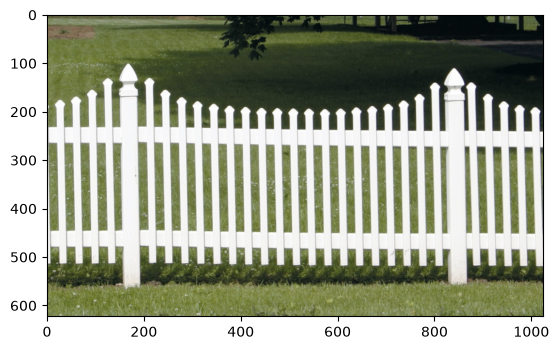

In [62]:
plt.figure()
plt.imshow(filtered_image1)

In [63]:
print(f"Identity Filter Works {np.allclose(F_IMAGE1,filtered_image1)}")

Identity Filter Works True


In [64]:
_statistics = %timeit -n 5 -r 2 -o image_filter(F_IMAGE1,filter_mask_id,NUMPROCESS,0,0)

8.53 s ± 272 ms per loop (mean ± std. dev. of 2 runs, 5 loops each)


In [65]:
print(_statistics)

8.53 s ± 272 ms per loop (mean ± std. dev. of 2 runs, 5 loops each)


In [66]:
print(vars(_statistics))

{'loops': 5, 'repeat': 2, 'best': 8.259763210599976, 'worst': 8.803571166599976, 'all_runs': [41.29881605299988, 44.017855832999885], 'compile_time': 4.400000000082116e-05, '_precision': 3, 'timings': [8.259763210599976, 8.803571166599976]}


# CASCADE FILTERING

In [ ]:
filter_h=np.array([
    [1,0,-1],
    [2,0,-2],
    [1,0,-1]
])
filter_v=np.array([
    [1,2,1],
    [0,0,0],
    [-1,-2,-1]
])

In [68]:
%time
filtered_image1 = image_filter(F_IMAGE1,filter_h,NUMPROCESS,1,1)
filtered_image2 = image_filter(filtered_image1,filter_v,NUMPROCESS,1,1)

CPU times: user 2 μs, sys: 0 ns, total: 2 μs
Wall time: 5.25 μs


# PARALLEL FILTERING

In [70]:
%time
(filterd_image1,filtered_image2)=parallel_filtering(F_IMAGE1, filter_h, filter_v, NUMPROCESS, 1,1)

CPU times: user 2 μs, sys: 0 ns, total: 2 μs
Wall time: 4.29 μs


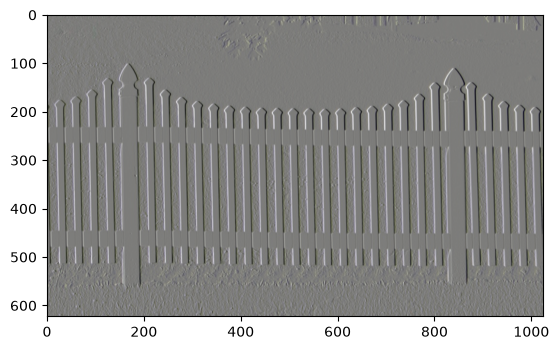

In [71]:
plt.figure()
plt.imshow(filtered_image1)

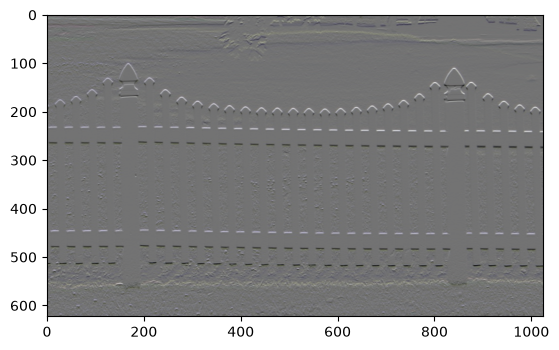

In [ ]:
plt.figure()
plt.imshow(filtered_image2)

# Visualisation
In these final cells, we take the filtered images stored in the multiprocessing.Vector variables filtered_image1_VECTOR and filtered_image2_VECTOR, convert them to NumPy arrays with the same shapes as the original images, and display the results.

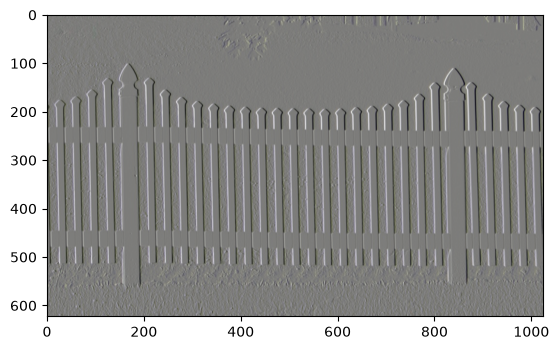

In [72]:
plt.figure()
plt.imshow(filtered_image1)

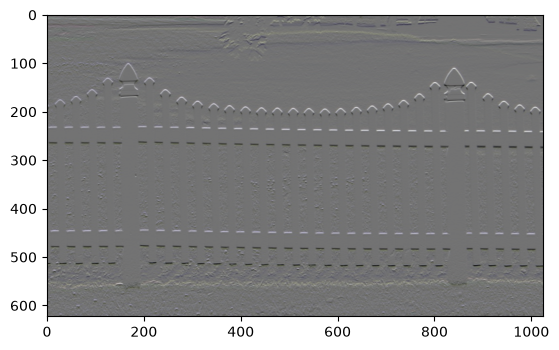

In [73]:
plt.figure()
plt.imshow(filtered_image2)

# ADD YOUR ADDITIONAL TESTS, ANALYSIS AND CONCLUSIONS AFTER THIS CELL

## Additional Tests

In [ ]:
# Identity 3x3 mask
print("--- Identity mask ---")
identity = np.zeros((3, 3), dtype=float)
identity[1, 1] = 1
identity_result = image_filter(F_IMAGE1, identity, NUMPROCESS, 0, 0)
print("Pixel-by-pixel identity:", np.array_equal(F_IMAGE1, identity_result))

# Create image with constant value 128 and apply a 5x5 averaging mask. The result should be the same constant value, 
# including the borders due to replicated boundary handling (no black borders).
print("\n--- Constant image and replicated boundary ---")
constant_image = np.full((12, 12, 3), 128, dtype=np.uint8)
constant_result = image_filter(constant_image, np.ones((5, 5)) / 25, NUMPROCESS, 0, 0)
print("All pixels, including borders, equal 128:", np.all(constant_result == 128))
print("Top-left replicated-boundary value:", constant_result[0, 0, 0])

# Create a bright image with pixel values of 250 and apply a sharpening mask. 
# The result should not have any dark pixels (values below 250) due to saturation.
print("\n--- Bright image and saturation ---")
bright_image = np.full((12, 12, 3), 250, dtype=np.uint8)
sharpen = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float)
bright_result = image_filter(bright_image, sharpen, NUMPROCESS, 0, 0)
print("No dark pixels after sharpening:", bright_result.min() >= 250)

# Validate that the function correctly rejects invalid masks.
print("\n--- Mask validation ---")
for invalid_mask in (np.ones((2, 3)), np.ones((7, 7))):
    try:
        image_filter(F_IMAGE1, invalid_mask, NUMPROCESS, 0, 0)
    except ValueError as error:
        print("Rejected invalid mask:", error)

# Apply three different masks to a real image.
print("\n--- Three masks on a real image ---")
gaussian = np.array([[1, 4, 6, 4, 1], [4, 16, 24, 16, 4],
                     [6, 24, 36, 24, 6], [4, 16, 24, 16, 4],
                     [1, 4, 6, 4, 1]], dtype=float) / 256
laplacian = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=float)
parallel_gaussian_laplacian = parallel_filtering(F_IMAGE1, gaussian, laplacian, NUMPROCESS, 0, 0)
smoothed = image_filter(F_IMAGE1, gaussian, NUMPROCESS, 0, 0)
cascade_gaussian_laplacian = image_filter(smoothed, laplacian, NUMPROCESS, 0, 0)
sharpened = image_filter(F_IMAGE1, sharpen, NUMPROCESS, 0, 0)
print("Parallel outputs:", [result.shape for result in parallel_gaussian_laplacian])
print("Cascade output:", cascade_gaussian_laplacian.shape)
print("Gaussian range:", int(parallel_gaussian_laplacian[0].min()), int(parallel_gaussian_laplacian[0].max()))
print("Laplacian range after rescaling:", int(parallel_gaussian_laplacian[1].min()), int(parallel_gaussian_laplacian[1].max()))
print("Sharpen range after saturation:", int(sharpened.min()), int(sharpened.max()))


# Comparison with library filtering function
from scipy.ndimage import uniform_filter

# Create a 3x3 averaging mask and apply our image_filter function to the first test image.
mean_mask_3x3 = np.ones((3, 3), dtype=float) / 9.0
our_filtered = image_filter(F_IMAGE1, mean_mask_3x3, NUMPROCESS, 0, 1)

# Use scipy's uniform_filter to apply a 3x3 averaging filter to the same image. 
# The uniform_filter function automatically handles boundary conditions, so we don't need to worry about that.
if F_IMAGE1.ndim == 3:
    scipy_filtered = np.stack([
        uniform_filter(F_IMAGE1[:, :, c].astype(float), size=3, mode='nearest')
        for c in range(F_IMAGE1.shape[2])
    ], axis=-1)
else:
    scipy_filtered = uniform_filter(F_IMAGE1.astype(float), size=3, mode='nearest')

scipy_filtered_uint8 = np.clip(np.rint(scipy_filtered), 0, 255).astype(np.uint8)

# Calculate the maximum absolute difference between our filtered image and the scipy filtered image.
max_difference = np.max(np.abs(our_filtered.astype(int) - scipy_filtered_uint8.astype(int)))
print(f"\n--- Library Comparison (scipy) ---")
print(f"Maximum absolute difference: {max_difference}")


--- Identity mask ---
Pixel-by-pixel identity: True

--- Constant image and replicated boundary ---
All pixels, including borders, equal 128: True
Top-left replicated-boundary value: 128

--- Bright image and saturation ---
No dark pixels after sharpening: True

--- Mask validation ---
Rejected invalid mask: The mask must have odd dimensions between 1x1 and 5x5.
Rejected invalid mask: The mask must have odd dimensions between 1x1 and 5x5.

--- Three masks on a real image ---
Parallel outputs: [(623, 1024, 3), (623, 1024, 3)]
Cascade output: (623, 1024, 3)
Gaussian range: 1 255
Laplacian range after rescaling: 0 255
Sharpen range after saturation: 0 255

--- Library Comparison (scipy) ---
Maximum absolute difference: 0


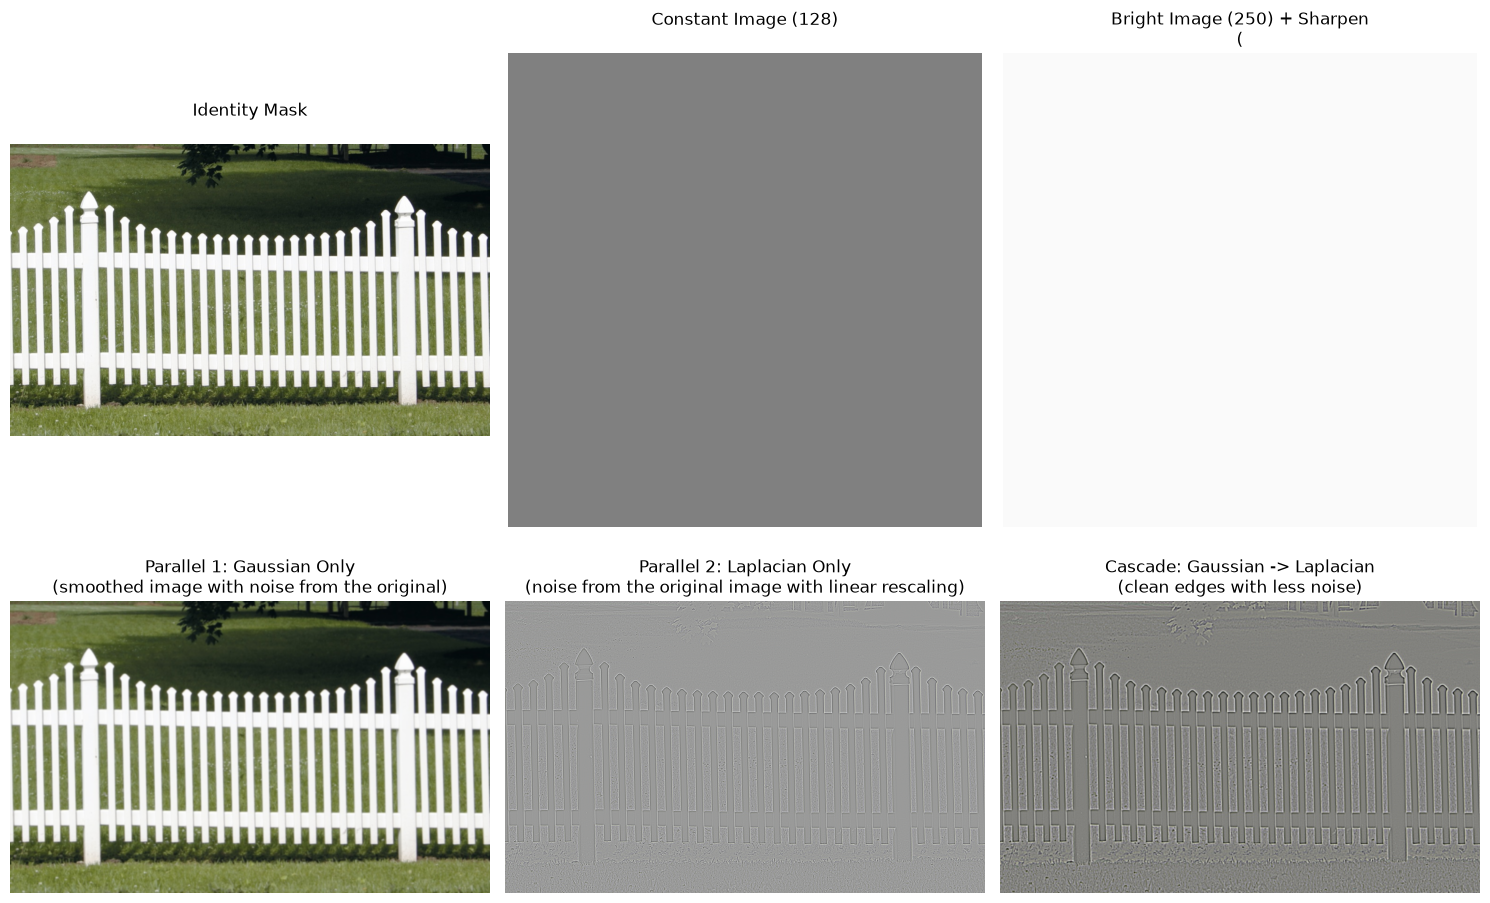

In [ ]:
# Visualization of the results
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Test 1: Identity Mask
axes[0, 0].imshow(identity_result)
axes[0, 0].set_title("Identity Mask\n")
axes[0, 0].axis('off')

# Test 2: Constant Image with Replicated Boundary
axes[0, 1].imshow(constant_result)
axes[0, 1].set_title("Constant Image (128)\n")
axes[0, 1].axis('off')

# Test 3: Bright Image with Saturation
axes[0, 2].imshow(bright_result)
axes[0, 2].set_title("Bright Image (250) + Sharpen\n(No dark pixels after sharpening)")
axes[0, 2].axis('off')

# Test 4: Parallel (Gaussian + Laplacian)
axes[1, 0].imshow(parallel_gaussian_laplacian[0])
axes[1, 0].set_title("Parallel 1: Gaussian Only\n(smoothed image with noise from the original)")
axes[1, 0].axis('off')

# Test 5: Parallel (Laplacian only with linear rescaling)
axes[1, 1].imshow(parallel_gaussian_laplacian[1])
axes[1, 1].set_title("Parallel 2: Laplacian Only\n(noise from the original image with linear rescaling)")
axes[1, 1].axis('off')

# Test 6: Cascade (Gaussian -> Laplacian)
axes[1, 2].imshow(cascade_gaussian_laplacian)
axes[1, 2].set_title("Cascade: Gaussian -> Laplacian\n(clean edges with less noise)")
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

### Analysis

**Identity Test:** Serves as a pixel-by-pixel control test, confirming that the image traversal, channel handling, and replicated boundaries preserve the input exactly when the central coefficient is $1$.   

**Boundary Replication:** Using a constant $5\times5$ mean image yields $128$ across both the interior and the corners, validating correct boundary stretching and ruling out zero-padding artifacts (such as dark borders).   

**Saturation and Overflow Protection:** Processing a bright image with the sharpening mask produces no dark pixels. Accumulation in float64, rounding only after the complete weighted sum, and final saturation strictly constrain values to $[0, 255]$.   

**Mask Validation and Filtering Effects:** Invalid dimensions ($2\times3$, $7\times7$) are explicitly rejected. The Gaussian, Laplacian, and sharpening masks successfully demonstrate smoothing, zero-sum edge enhancement with global rescaling, and local contrast enhancement, respectively.   

**Parallel vs. Sequential Execution:** Parallel filtering applies independent masks to the original image simultaneously, whereas sequential filtering (cascade) passes Gaussian-smoothed output into a Laplacian filter. The cascade successfully suppresses high-frequency noise prior to edge detection, demonstrating that processing order is critical.   

**Linear Rescaling:** For zero-sum masks, the displayed $[0, 255]$ range is achieved via linear rescaling of signed responses rather than clipping, preserving both positive and negative edge polarities for visual comparison.  



## Conclusions

- Algorithmic Compliance: The implementation fully satisfies the core constraints by executing explicit loops over pixels and mask coefficients, supporting odd mask dimensions from $1\times1$ to $5\times5$, handling RGB channels independently, and replicating boundary pixels.   

- Parallel Architecture & Concurrency: Utilizing a multiprocessing.Pool with shared input/output memory (mp.RawArray) achieves efficient medium-grained parallelism. Because worker processes operate on disjoint, exclusive row intervals, data races are inherently avoided, rendering explicit locks unnecessary.   

- Convolution vs. Correlation: The is_conv flag correctly distinguishes correlation from convolution by rotating asymmetric kernels (such as Sobel) by $180^\circ$, while yielding identical results for symmetric masks.   

- Numerical Stability: Accumulating values in a wider floating-point type (float64), followed by rounding and saturation (or linear rescaling for zero-sum filters), prevents silent integer overflows and ensures accurate radiometric representation.   

- Practical Implications: The experiments confirm robust identity preservation, correct boundary handling, protection against integer wrap-around, and effective parallel/sequential execution. Sequential Gaussian-then-Laplacian filtering is optimal when noise reduction is required before edge detection, whereas parallel filtering is ideal for comparing distinct spatial operations side by side. 
